![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 01 | Framing and Baseline

*Project 3 — AI Product: From Model to Product*

**Team:** Zoé Doucet

**Track:** LLM

**Data:** Forest Entomology and Pathology

---

Frame the product, look at the data, fix your evaluation before you build anything, and score the baseline your solution will have to beat.

> **Done when:** your framing is written down, you know what one row or one document is and what is wrong with the data, your test set or evaluation set is fixed, and you can say your metric and your baseline score out loud.

---
## 0. Setup

In [2]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *
from pypdf import PdfReader

pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")

---
## 1. Frame the product

Before any code. In a few sentences:

- **The user:** The typical user is someone who has a connection to nature but is not an expert in forestry. This could range from a curious garden owner to someone who owns a small plot of forest.

- **The input and output:** The final product will be a chatbot. Users will be able to ask questions or describe symptoms observed on a tree, such as signs of disease like insect infestations. The chatbot will respond with possible explanations based on the available scientific information or ask clarifying questions when more details are needed.

- **The decision:** The chatbot will help users better understand the possible causes of their tree's symptoms and decide whether they should seek further information or professional assistance.

- **The metric:** The chatbot will be evaluated using a set of predefined questions and symptom descriptions. The retrieval system will be assessed by measuring how often it identifies relevant passages from the reference book. The generated answers will be evaluated for factual accuracy, relevance, and whether they are supported by the retrieved information. The chatbot will be restricted to answering questions about tree health using only information from the reference book. It will not access external sources. The most costly mistake would be providing an incorrect or misleading answer, as this could cause users to misidentify a tree pest or take inappropriate action. An answer without supporting evidence is also problematic because users cannot verify the information. A refusal to answer is less harmful when the available evidence is insufficient. Therefore, the chatbot will be instructed to answer only when the textbook provides relevant information, clearly communicate uncertainty, and acknowledge when it cannot provide a reliable answer.I f the user provides insufficient information or the book does not contain the necessary evidence, the chatbot must acknowledge this rather than provide an unsupported answer.

You wrote a first version on launch day. Refine it here.

---
## 2. Load the data

Run `python download_data.py` (or `python download_data.py clothing`) from the repo root first. Your files land in `data/raw/`, which is gitignored.

In [3]:
reader = PdfReader("../data/raw/Forest_Entomology_and_Pathology.pdf")
print(len(reader.pages), "pages")

810 pages


---
## 3. First look

Shape, columns, a handful of rows **read in full**. What is one row? For the Amazon data, join a few reviews to their product in the metadata file on `parent_asin`.

In [4]:
# extracting text from one page
page = reader.pages[10]

text = page.extract_text()

print(text[:1500])

Contributors xi
Hervé´ Jactel´INRAE,´ University´ of´ Bordeaux,´ BIOGECO,´ Cestas,´ Bordeaux,´
France´
Paal´ Krokene´Division´ of´ Biotechnology´ and´ Plant´ Health,´ Norwegian´ Institute´ of´
Bioeconomy´ Research,´ Ås,´ Norway´
Stig´ Larsson´Swedish´ University´ of´ Agricultural´ Sciences,´ Uppsala,´ Sweden´
Andrew´ M.´ Liebhold´US´ Forest´ Service´ Northern´ Research´ Station,´ Morgantown,´
WV,´ USA´
Maria´ J.´ Lombardero´Unidade´ de´ Xestion´ Ambiental´ E´ Forestal´ Sostible,´ Univer-
sidade´ de´ Santiago´ de´ Compostela,´ Lugo,´ Spain´
Alex´ C.´ Mangini´Southern´ Region,´ Forest´ Health´ Protection,´ USDA´ Forest´ Service,´
Pineville,´ LA,´ USA´
Deborah´ G.´ McCullough´Department´ of´ Entomology´ and´ Department´ of´ Forestry,´
Michigan´ State´ University,´ East´ Lansing,´ MI,´ USA´
Zvi´ Mendel´Department´ of´ Entomology,´ Agriculture´ Research´ Organization,´ The´
V olcani´ Center,´ Bet´ Dagan,´ Israel´
Daniel´ R.´ Miller´USDA´ Forest´ Service,´ Southern´ Research´ Station,´ Athen

In [5]:
# extracting text from a few pages
for page_number in [0, 10, 50, 100]:
    text = reader.pages[page_number].extract_text() or ""

    print(f"\n--- PDF page {page_number + 1} ---")
    print(text[:500])


--- PDF page 1 ---


--- PDF page 11 ---
Contributors xi
Hervé´ Jactel´INRAE,´ University´ of´ Bordeaux,´ BIOGECO,´ Cestas,´ Bordeaux,´
France´
Paal´ Krokene´Division´ of´ Biotechnology´ and´ Plant´ Health,´ Norwegian´ Institute´ of´
Bioeconomy´ Research,´ Ås,´ Norway´
Stig´ Larsson´Swedish´ University´ of´ Agricultural´ Sciences,´ Uppsala,´ Sweden´
Andrew´ M.´ Liebhold´US´ Forest´ Service´ Northern´ Research´ Station,´ Morgantown,´
WV,´ USA´
Maria´ J.´ Lombardero´Unidade´ de´ Xestion´ Ambiental´ E´ Forestal´ Sostible,´ Univer-
sidade´

--- PDF page 51 ---
40 D. Doucet and T. D. Paine
Carlson´ RW´ (1983)´ Instar,´ stadium,´ and´ stage:´ deﬁnitions´ to´ ﬁt´ usage.´ Ann´ Entomol´ Soc´ Am´
76(3):319–319´
Casari´ SA,´ Teixeira´ ÉP´ (2014)´ Immatures´ of´ Acanthocinini´ (Coleoptera,´ Cerambycidae,´ Lamiinae).´
Rev´ Bras´ Entomol´ 58(2):107–128´
Cavaletto´ G,´ Faccoli´ M,´ Marini´ L,´ Spaethe´ J,´ Giannone´ F,´ Moino´ S,´ Rassati´ D´ (2020)´ Exploiting´
trap´ color´ to´ improve´ surveys´ of

The first inspection shows that text extraction is possible, but some formatting issues occur, including unwanted backticks, accents, line breaks, and words split across lines. The PDF also contains introductory material, such as contributor lists, that may not be relevant for retrieval. before building the RAG pages taht can be excluded should be identified.

In [6]:
pages = []

for i, page in enumerate(reader.pages):
    text = page.extract_text() or ""

    pages.append({
        "pdf_page": i + 1,
        "text": text})

df = pd.DataFrame(pages)

df.head()

,pdf_page,text
0,1,
1,2,Forest´ Entomology´ and´ Pathology
2,3,Jeremy´ D.´ Allison´· Timothy´ D.´ Paine´· \nBernard´ Slippers´· Michael´ J.´ Wingﬁeld´\nEditors´\nForest´ Entomology´\nand´ Pathology´\nV olume´ 1:´ Entomology
3,4,"Editors \nJeremy´ D.´ Allison´\nNatural´ Resources´ Canada´\nSault´ Ste.´ Marie,´ ON,´ Canada´\nBernard´ Slippers´\nForestry´ and´ Agricultural´ Biotechnology´\nInstitute´\nUniversity´ of´ Pretori..."
4,5,"Preface´\nThe´ idea´ for´ this´ book´ emerged´ from´ conversations´ between´ the´ editors,´ in´ particular´\nduring´ visits´ by´ JDA´ to´ South´ Africa´ to´ work´ with´ BS´ on´ plantation´ pests´ ..."


---
## 4. Data quality

Empty and very short texts, HTML (`<br />`, `&#34;`), duplicates, texts in other languages, missing titles or metadata. Write down what you find and what you will do about it. Put the cleaning in a function in `src/functions.py`: the app will need it too.

### 4.1 Text length and content

In [7]:
# number of empty pages
empty = (df["text"].str.strip() == "").sum()
print(empty)

1


In [8]:
# numbr of duplicate pages
duplicates = df["text"].duplicated().sum()
print(duplicates)

0


In [9]:
# length of text on each page
text_length = df["text"].str.len()
round(text_length.describe(), 2)

count     810.00
mean     3118.09
std      1056.02
min         0.00
25%      2383.00
50%      3357.50
75%      3903.25
max      4913.00
Name: text, dtype: float64

In [10]:
# checking for very short pages
df["text_length"] = df["text"].str.len()

short_pages = df[df["text_length"] < 200]

print("Pages with fewer than 200 characters:", len(short_pages))

display(short_pages[["pdf_page", "text_length"]].head(20))

Pages with fewer than 200 characters: 3


,pdf_page,text_length
0,1,0
1,2,34
2,3,155


In [11]:
# checking the content of short pages
for pdf_page in [1, 2, 3]:
    print(f"\n--- PDF page {pdf_page} ---")
    print(df.loc[pdf_page - 1, "text"])


--- PDF page 1 ---


--- PDF page 2 ---
Forest´ Entomology´ and´ Pathology

--- PDF page 3 ---
Jeremy´ D.´ Allison´· Timothy´ D.´ Paine´· 
Bernard´ Slippers´· Michael´ J.´ Wingﬁeld´
Editors´
Forest´ Entomology´
and´ Pathology´
V olume´ 1:´ Entomology


In [12]:
# checking the content of first and last pages
for i in list(range(5)) + list(range(len(df) - 5, len(df))):
    print(f"\n--- PDF page {i + 1} ---")
    print(df.loc[i, "text"][:250])


--- PDF page 1 ---


--- PDF page 2 ---
Forest´ Entomology´ and´ Pathology

--- PDF page 3 ---
Jeremy´ D.´ Allison´· Timothy´ D.´ Paine´· 
Bernard´ Slippers´· Michael´ J.´ Wingﬁeld´
Editors´
Forest´ Entomology´
and´ Pathology´
V olume´ 1:´ Entomology

--- PDF page 4 ---
Editors 
Jeremy´ D.´ Allison´
Natural´ Resources´ Canada´
Sault´ Ste.´ Marie,´ ON,´ Canada´
Bernard´ Slippers´
Forestry´ and´ Agricultural´ Biotechnology´
Institute´
University´ of´ Pretoria´
Hatﬁeld,´ South´ Africa´
Timothy´ D.´ Paine´
Department´ o

--- PDF page 5 ---
Preface´
The´ idea´ for´ this´ book´ emerged´ from´ conversations´ between´ the´ editors,´ in´ particular´
during´ visits´ by´ JDA´ to´ South´ Africa´ to´ work´ with´ BS´ on´ plantation´ pests´ and´ the´
ecology´ of´ invasive´ forest´ insects.´ In´ t

--- PDF page 806 ---
806 A. M. Liebhold et al.
Boyd IL, Freer-Smith PH, Gilligan CA, Godfray HCJ (2013) The consequence of tree pests and 
diseases for ecosystem services. Science 342:1235773 
Brockerhoff 

In [13]:
# makinf sure all text is in english
for page_number in [50, 150, 300, 450, 700]:
    text = df.loc[page_number, "text"]

    print(f"\n--- PDF page {page_number + 1} ---")
    print(text[:300])


--- PDF page 51 ---
40 D. Doucet and T. D. Paine
Carlson´ RW´ (1983)´ Instar,´ stadium,´ and´ stage:´ deﬁnitions´ to´ ﬁt´ usage.´ Ann´ Entomol´ Soc´ Am´
76(3):319–319´
Casari´ SA,´ Teixeira´ ÉP´ (2014)´ Immatures´ of´ Acanthocinini´ (Coleoptera,´ Cerambycidae,´ Lamiinae).´
Rev´ Bras´ Entomol´ 58(2):107–128´
Cavaletto´ 

--- PDF page 151 ---
142 J.-C. Grégoire and J. R. Gould
6.2´ Natural´ Enemies´
Any organism feeding on another species or group of species during at least one 
developmental stage can be described as a “natural enemy”, a category to which 
predators, parasitoids and pathogens attacking forest insects obviously belong. T

--- PDF page 301 ---
9 Foliage Feeders 293
Sharov´ AA,´ Roberts´ EA,´ Liebhold´ AM´ et´ al´ (1995)´ Gypsy´ moth´ (Lepidoptera:´ Lymantriidae)´ spread´
in´ the´ central´ Appalachians:´ three´ methods´ for´ species´ boundary´ estimation.´ Environ´ Entomol´
24(6):1529–1538.´https://doi.org/10.1093/ee/24.6.1529´
Sharov´ AA,

--- PDF page 451 ---
446 M. Bra

The book only has one empty page
The book has zero duplicate pages
page legth is okay
only three pages with fewer than 200 characters: pages 1,2 and 3.


### 4.2 special characters

In [14]:
# counting the number of pages containing backticks and accents
df["backtick_count"] = df["text"].str.count("`")
df["acute_count"] = df["text"].str.count("´")

print("Pages containing backticks:", (df["backtick_count"] > 0).sum())
print("Pages containing acute accents:", (df["acute_count"] > 0).sum())

Pages containing backticks: 60
Pages containing acute accents: 427


In [15]:
# checking for httml and other artifacts
html_pattern = r"<(?:div|p|span|br|html|body)\b[^>]*>"

html_pages = df[
    df["text"].str.contains(
        html_pattern,
        case=False,
        regex=True,
        na=False)]

print("Pages with HTML-like tags:", len(html_pages))

Pages with HTML-like tags: 0


In [16]:
# checking for line break hyphenation
hyphenated_pages = df[
    df["text"].str.contains(r"\w-\s*\n\s*\w", regex=True, na=False)]

print("Pages with line break hyphenation:", len(hyphenated_pages))

Pages with line break hyphenation: 622


#### 4.4 Page number match

In [17]:
# checking page number matches
print("Missing page numbers:", df["pdf_page"].isna().sum())
print("Missing text values:", df["text"].isna().sum())
print("Unique page numbers:", df["pdf_page"].nunique())

Missing page numbers: 0
Missing text values: 0
Unique page numbers: 810


In [18]:
# checking for page offset
for pdf_page in [30, 50, 101, 150, 300, 500, 700]:
    text = df.loc[pdf_page - 1, "text"]

    print(f"\nPDF page {pdf_page}")
    print("Beginning:", repr(text[:120]))
    print("End:", repr(text[-120:]))


PDF page 30
Beginning: 'Chapter 2 \nForm and Function \nDaniel Doucet and Timothy D. Paine \nInsect´ form´ and´ function´ is´ a´ vast´ ﬁeld´ of´ kn'
End: '23´\nJ.´ D.´ Allison´ et´ al.´ (eds.),´F orest Entomology and Pathology,´\nhttps://doi.org/10.1007/978-3-031-11553-0_2´\n19'

PDF page 50
Beginning: '2 Form and Function 39\nchromosomes),´ known´ as´ haplo-diploid´ sex´ determination.´ As´ a´ consequence,´ in´\nmany´ spec'
End: 'ects:´ a´ review´ and´ synthesis´ of´ size-and´\nbrain-dependent´ and´ independent´ mechanisms.´ Biol´ Rev´ 88(4):944–954'

PDF page 101
Beginning: 'Chapter 4 \nInsect Ecology \nLaurel J. Haavik and Fred M. Stephen \n4.1 Introduction \nInsect` ecology` is` the` study` of` '
End: '23`\nJ.` D.` Allison` et` al.` (eds.),`F orest Entomology and Pathology,`\nhttps://doi.org/10.1007/978-3-031-11553-0_4`\n91'

PDF page 150
Beginning: 'Chapter´ 6´\nForest´ Insect–Natural´ Enemy´\nInteractions´\nJean-Claude´ Grégoire´ and´ Juli´ R.´ Gould´\n6.1´ Introduction´'
End: '

### Data quality inspection findings

The dataset consists of an 810-page scientific textbook extracted using `pypdf`. Each row represents one PDF page and contains the extracted text and a unique PDF page number.

The initial quality checks found one empty page (PDF page 1) and no duplicate pages. PDF pages 2 and 3 contain introductory title and editor information rather than scientific content and can be therefore excluded from searchable content.

The extraction contains several formatting artifacts. Backticks occur on 60 pages, acute-accent characters (`´`) occur on 427 pages, and line-break hyphenation occurs on 626 pages. Other observed issues include unusual circumflex-like characters, split words, and ligatures.

The scientific text appears to be predominantly English. No HTML tags were detected, although DOI and HTTP links appear in the text.

The printed textbook page numbers differ from PDF page numbers, and the offset is not constant. Therefore, PDF page numbers will be preserved as reliable source identifiers for the initial RAG system.

The book contains reference lists at the end of individual chapters, rather than one bibliography at the end. These sections may be less useful for answering user questions and should be considered during document preparation.

**Planned preprocessing:** Normalize confirmed extraction artifacts, repair line-break hyphenation, and normalize whitespace. The original extracted text will be preserved for comparison. Empty pages and irrelevant front matter will be excluded from retrieval, while chapter-level reference sections will be assessed before filtering.

#### 4.5 Cleaning the data

In [19]:
# testing the cleaning function on a sample
sample = "Insect` ecology` is` the` study` of` the` environ-\nment."

print("Before:", sample)
print("After: ", clean_text(sample))

Before: Insect` ecology` is` the` study` of` the` environ-
ment.
After:  Insect ecology is the study of the environment.


The cleaning works well on the sample.

In [20]:
# cleaning the text
df["clean_text"] = df["text"].apply(clean_text)

df[["pdf_page", "text", "clean_text"]].head()

,pdf_page,text,clean_text
0,1,,
1,2,Forest´ Entomology´ and´ Pathology,Forest Entomology and Pathology
2,3,Jeremy´ D.´ Allison´· Timothy´ D.´ Paine´· \nBernard´ Slippers´· Michael´ J.´ Wingﬁeld´\nEditors´\nForest´ Entomology´\nand´ Pathology´\nV olume´ 1:´ Entomology,Jeremy D. Allison · Timothy D. Paine · Bernard Slippers · Michael J. Wingfield Editors Forest Entomology and Pathology V olume 1: Entomology
3,4,"Editors \nJeremy´ D.´ Allison´\nNatural´ Resources´ Canada´\nSault´ Ste.´ Marie,´ ON,´ Canada´\nBernard´ Slippers´\nForestry´ and´ Agricultural´ Biotechnology´\nInstitute´\nUniversity´ of´ Pretori...","Editors Jeremy D. Allison Natural Resources Canada Sault Ste. Marie, ON, Canada Bernard Slippers Forestry and Agricultural Biotechnology Institute University of Pretoria Hatfield, South Africa Tim..."
4,5,"Preface´\nThe´ idea´ for´ this´ book´ emerged´ from´ conversations´ between´ the´ editors,´ in´ particular´\nduring´ visits´ by´ JDA´ to´ South´ Africa´ to´ work´ with´ BS´ on´ plantation´ pests´ ...","Preface The idea for this book emerged from conversations between the editors, in particular during visits by JDA to South Africa to work with BS on plantation pests and the ecology of invasive fo..."


The cleaning seems to work on the text as well. However let's check a few pages.

In [21]:
# checking a few pages
for pdf_page in [101, 150, 500]:
    row = df[df["pdf_page"] == pdf_page].iloc[0]

    print(f"\n--- PDF page {pdf_page} ---")
    print(row["clean_text"][:700])


--- PDF page 101 ---
Chapter 4 Insect Ecology Laurel J. Haavik and Fred M. Stephen 4.1 Introduction Insect ecology is the study of how insects interact with the environment. The environment consists of both physical characteristics (abiotic) and other organisms (biotic). Insects are natural components of forests and perform a variety of essential functions that help maintain forests as ecosystems. As consumers of forest products, people sometimes compete with insects for forest resources. Most research and management efforts in forest entomology have focused on insects that damage or kill large numbers of ecologically or economically important trees. In this chapter, we consider the various environmental challen

--- PDF page 150 ---
Chapter 6 Forest Insect–Natural Enemy Interactions Jean-Claude Grégoire and Juli R. Gould 6.1 Introduction As illustrated in several other chapters of this book, “forest insects”, including those linked to woody plants growing outside the forest environme

In [22]:
# checking for remaining artifacts
for char in ["`", "´", "ˆ", "\u0301", "\u0302"]:
    count = df["clean_text"].str.contains(
        char, regex=False).sum()

    print(f"{repr(char)}: {count} pages")

'`': 0 pages
'´': 0 pages
'ˆ': 0 pages
'́': 0 pages
'̂': 0 pages


### Cleaning validation

The cleaning function was tested on scientific text from PDF pages 101, 150, and 500. The cleaned passages were readable and preserved the scientific explanations and species names.

After cleaning, none of the 810 pages contained the five checked extraction artifacts: backticks, acute-accent marks, circumflex-like marks, or their combining-character equivalents.

Some minor formatting issues remain, including occasional spaces within words. These were left unchanged to avoid introducing errors through overly aggressive cleaning.

The cleaned text is considered suitable for the initial retrieval baseline. The original text remains available for comparison.

---
## 5. Look at the texts

Lengths, the most frequent words, how the texts differ between ratings, products or periods. Read some hard cases: the 3-star reviews, the sarcastic ones, the ones whose rating and text disagree.

In [23]:
# taking a look at the cleaned text length
df["clean_text_length"] = df["clean_text"].str.len()

df["clean_text_length"].describe()

count     810.000000
mean     2903.859259
std       969.022439
min         0.000000
25%      2221.000000
50%      3195.000000
75%      3625.500000
max      4300.000000
Name: clean_text_length, dtype: float64

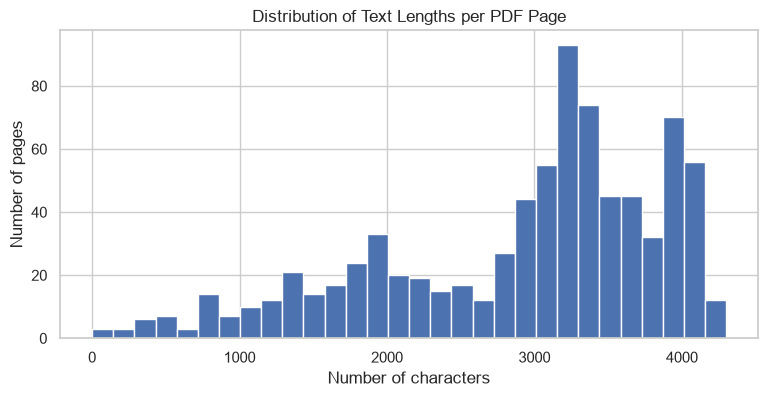

In [24]:
plt.figure(figsize=(9, 4))

plt.hist(df["clean_text_length"], bins=30)

plt.title("Distribution of Text Lengths per PDF Page")
plt.xlabel("Number of characters")
plt.ylabel("Number of pages")

plt.show()

In [25]:
# taking a closer look at the longest and shortest pages
print("Shortest pages:")
display(df.nsmallest(5, "clean_text_length")[
        ["pdf_page", "clean_text_length", "clean_text"]])

print("Longest pages:")
display(df.nlargest(5, "clean_text_length")[
        ["pdf_page", "clean_text_length", "clean_text"]])

Shortest pages:


,pdf_page,clean_text_length,clean_text
0,1,0,
1,2,31,Forest Entomology and Pathology
2,3,140,Jeremy D. Allison · Timothy D. Paine · Bernard Slippers · Michael J. Wingfield Editors Forest Entomology and Pathology V olume 1: Entomology
606,607,236,"17 IPM: The Forest Context 605 Fig. 17.11 Insecticides used for management of spruce budworm, Choristoneura fumiferana,i n Canada (Figure credit: C.J.K. MacQuarrie, Natural Resources Canada; repro..."
685,686,255,684 E. G. Brockerhoff et al. Fig. 19.8 Advertising used for the “Catch it - call us” campaign by New Zealand’s national biosecurity agency MPI to encourage reporting finds of an invasive insect. S...


Longest pages:


,pdf_page,clean_text_length,clean_text
518,519,4300,"15 Tip, Shoot, Root, and Regeneration Pests 515 Coyle DR, Nebeker TE, Hart ER, Mattson WJ Jr (2005) Biology and management of insect pests in North American intensively-managed hardwood forest sys..."
286,287,4279,9 Foliage Feeders 279 Embree DG (1967) Effects of winter moth on growth and mortality of red oak in Nova Scotia. For Sci 13(3):295–299. https://academic.oup.com/forestscience/article-abstract/13/3...
570,571,4244,"568 W. B. Strong et al. Barbosa P , Hines J, Kaplan I, Martinson H, Szczepaniec A, Szendrei Z (2009) Associational resistance and associational susceptibility: having right or wrong neighbors. Ann..."
96,97,4234,"3 Forest Arthropod Diversity 87 Schabel H (2010) Forest insects as food: a global review. In: Durst PB, Johnson DV , Leslie RN, Shono K (eds) Forest insects as food: humans bite back. Proceedings ..."
291,292,4231,"284 J. Elkinton and A. Roehrig Kenis M, Hurley BP , Hajek AE et al (2017) Classical biological control of insect pests of trees: facts and figures. Biol Invasions 19:3401–3417. https://doi.org/10...."


cleaned text legth slightly shorter but not to much. distribution not normal one peak around 2000 and one peak arround 3000.

#### 5.2 Most frequent words

In [26]:
from sklearn.feature_extraction.text import CountVectorizer

In [27]:
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=20)

word_matrix = vectorizer.fit_transform(df["clean_text"])

word_counts = word_matrix.sum(axis=0).A1

frequent_words = pd.DataFrame({"word": vectorizer.get_feature_names_out(), "count": word_counts}).sort_values("count", ascending=False)

display(frequent_words)

,word,count
1,al,3419
6,et,3400
17,species,2263
7,forest,2154
12,insects,1473
11,insect,1433
19,trees,1314
15,pine,1116
3,beetle,1086
18,tree,1072


### Text exploration findings

After cleaning, the dataset still contains 810 PDF pages, including one empty page. The average cleaned text length is approximately 2,904 characters per page, with a median of 3,195 characters and a maximum of 4,300 characters.

The cleaned text is slightly shorter than the original because extraction artifacts and unnecessary whitespace were removed.

The shortest pages are mainly introductory pages or pages near chapter endings. The longest pages contain dense text with no images.

The most frequent words include expected  terms such as *species*, *forest*, *insects*, *trees*, *pine*, *beetle*, and *host*. However, words such as *et*, *al*, *https*, *org*, and *entomol* also appear frequently, suggesting that bibliographic references contribute substantially to the text.

This may affect retrieval quality because a search could return bibliography entries instead of explanatory passages. During document preparation, I will investigate how to handle reference-heavy content while preserving useful scientific information.

Overall, the cleaned text appears suitable for building an initial retrieval system.

---
## 6. The baseline

The simplest thing that could work, scored with the same evaluation as your final solution.

- **Model track:** a `DummyClassifier`, then TF-IDF with logistic regression, scored with cross-validation on the training set.
- **LLM track:** the LLM alone (no retrieval, no tools) on your evaluation set, or a keyword search (TF-IDF) for the retrieval part. Log the tokens and the cost.

In [33]:
# Excluding empty and introductory pages
searchable_pages = df[
    (df["pdf_page"] > 12) & # Keep the actual textbook content, starting at PDF page 14
    (df["clean_text"].str.strip() != "")].copy()

print("Pages available for retrieval:", len(searchable_pages))

Pages available for retrieval: 798


#### 6.1 Chunking

In [34]:
import importlib
import src.functions

importlib.reload(src.functions)

from src.functions import chunk_document

chunks = chunk_document(searchable_pages, size=150, overlap=30)

print("Number of chunks:", len(chunks))
print("\nFirst chunk:")
print(chunks[0])

Number of chunks: 3274

First chunk:
{'id': 'page_13_chunk_0', 'text': 'Chapter 1 Introduction to and Importance of Insects Richard Redak 1.1 Introduction Insects and closely related arthropods are the dominant and most diverse forms of terrestrial and aquatic (non-marine) animal life on the planet. Other than marine systems, insects occupy every conceivable environment and habitat on the Earth. Crustaceans and Annelids (worms) are the dominant and most diverse groups of animals in marine systems. The dominance of insects is true in terms of diversity (number of species), numbers of individuals, and total biomass within a given area. As of this writing, there are approximately one million known species of insects (species that have been scientifically described—they have been provided a scientific name and their evolutionary relationship to other species is relatively well established). The known number of insect species is only a fraction of the estimated total number of species. The 

#### 6.2 Building the evaluation set

In [45]:
# Keywords for all 12 evaluation questions
topics = {
    "Q01": ["beneficial insects", "insect species"],
    "Q02": ["bark beetle", "outbreak"],
    "Q03": ["leaf miners", "leaf tissue"],
    "Q04": ["carya", "ulmus"],
    "Q05": ["predaceous insects", "woodborers"],
    "Q06": ["entrance holes", "resin"],
    "Q07": ["needles", "defoliation"],
    "Q08": ["leaf miners", "leaf damage"],
    "Q09": ["leaf tissue", "foliage feeding"],
    "Q10": ["spruce bark beetle", "windthrown"],
    "Q11": ["drought", "defensive capabilities"],
    "Q12": ["dead wood", "moribund trees"]
}

# Searching chunks using the keywords
for question, words in topics.items():
    matches = [
        chunk for chunk in chunks
        if any(word in chunk["text"].lower() for word in words)]

    print(f"{question}: {len(matches)} matching chunks")

    # Show the first two matching chunks
    for chunk in matches[:2]:
        print(f"  {chunk['id']}")

Q01: 104 matching chunks
  page_13_chunk_0
  page_13_chunk_120
Q02: 838 matching chunks
  page_14_chunk_0
  page_14_chunk_120
Q03: 9 matching chunks
  page_33_chunk_120
  page_33_chunk_240
Q04: 12 matching chunks
  page_277_chunk_120
  page_277_chunk_240
Q05: 109 matching chunks
  page_102_chunk_0
  page_102_chunk_120
Q06: 92 matching chunks
  page_110_chunk_240
  page_111_chunk_0
Q07: 203 matching chunks
  page_60_chunk_0
  page_65_chunk_240
Q08: 6 matching chunks
  page_33_chunk_120
  page_33_chunk_240
Q09: 9 matching chunks
  page_109_chunk_120
  page_116_chunk_120
Q10: 47 matching chunks
  page_111_chunk_360
  page_120_chunk_360
Q11: 93 matching chunks
  page_24_chunk_240
  page_28_chunk_120
Q12: 47 matching chunks
  page_62_chunk_240
  page_62_chunk_360


In [46]:
# Verifying supporting chunks for Q01–Q12
sources = {
    "Q01": "page_14_chunk_0",
    "Q02": "page_140_chunk_0",
    "Q03": "page_245_chunk_120",
    "Q04": "page_325_chunk_360",
    "Q05": "page_392_chunk_0",
    "Q06": "page_326_chunk_240",
    "Q07": "page_65_chunk_240",
    "Q08": "page_245_chunk_120",
    "Q09": "page_245_chunk_120",
    "Q10": "page_111_chunk_360",
    "Q11": "page_24_chunk_240",
    "Q12": "page_62_chunk_360"
}

# Find chunks directly by ID
lookup = {chunk["id"]: chunk for chunk in chunks}

# Print each unique source once
for id in dict.fromkeys(sources.values()):
    chunk = lookup[id]

    print(f"\n{id} | PDF page {chunk['pdf_page']}")
    print(chunk["text"])
    print("-" * 60)


page_14_chunk_0 | PDF page 14
2 R. Redak Fig. 1.1 The relative proportions of described species on the planet. © Matt Leatherman The overwhelming majority of insect species are not harmful to human health, commerce, or agriculture, and in some form or fashion are actually beneficial. Worldwide, less than 1% of all known insect species are pests either destroying/damaging food and fiber resources, stored products, structures, or transmitting diseases. Within forest ecosystems, several insect species are serious pests that threaten our use of these natural resources and the ecosystem services they provide. In short, insects are our greatest competitors for the resources required to sustain our lives. Those few species that are pests result in tremendous efforts to manage their populations and limit the damage they cause. As the impacts of forest pests (especially undergoing outbreak infestations as shown in Fig. 1.8) are exceptionally visible, the value and benefit of most insect specie

In [48]:
# Questions with verified textbook evidence
evaluation_data = [
    {
        "question_id": "Q01",
        "question": "Are most insects harmful, or are many of them beneficial?",
        "answerable": True,
        "page": "14",
        "answer": "Most insects are not harmful and many are beneficial. Fewer than 1% of known insect species are considered pests."
    },
    {
        "question_id": "Q02",
        "question": "Do all bark beetle species cause major outbreaks in forests?",
        "answerable": True,
        "page": "140",
        "answer": "No. Only a small minority of bark beetle species are outbreak species."
    },
    {
        "question_id": "Q03",
        "question": "What is the difference between insects that eat leaves and leaf miners?",
        "answerable": True,
        "page": "245",
        "answer": "Some insects feed externally on leaves, while leaf miners feed between the upper and lower leaf surfaces as larvae."
    },
    {
        "question_id": "Q04",
        "question": "Can bark beetles attack hardwood trees as well as conifers?",
        "answerable": True,
        "page": "325",
        "answer": "Yes. Some bark beetles attack hardwoods, including species of Carya and Ulmus."
    },
    {
        "question_id": "Q05",
        "question": "What animals or insects naturally help control woodboring beetles?",
        "answerable": True,
        "page": "392",
        "answer": "Predatory insects help regulate woodborer populations. Some woodboring beetles are also prey for birds, bats, lizards and other animals."
    },
    {
        "question_id": "Q06",
        "question": "My pine tree has small holes in its bark. Could insects be responsible?",
        "answerable": True,
        "page": "326",
        "answer": "Yes. Some bark beetles, such as Tomicus species, create entrance holes surrounded by resin. Holes alone do not confirm the cause."
    },
    {
        "question_id": "Q07",
        "question": "My pine tree is losing its needles. Could insects be causing this?",
        "answerable": True,
        "page": "65",
        "answer": "Yes. Some insects feed on needles and can cause defoliation, but needle loss alone does not identify the cause."
    },
    {
        "question_id": "Q08",
        "question": "Some leaves on my tree have unusual patterns inside them. Could insects be responsible?",
        "answerable": True,
        "page": "245",
        "answer": "Yes. Leaf-mining larvae feed between the upper and lower leaf surfaces and produce characteristic damage patterns."
    },
    {
        "question_id": "Q09",
        "question": "Some leaves on my tree have missing tissue. Could insects be responsible?",
        "answerable": True,
        "page": "245",
        "answer": "Yes. Some foliage-feeding insects feed externally on leaves and remove or consume leaf tissue, sometimes including the leaf veins."
    },
    {
        "question_id": "Q10",
        "question": "Can European spruce bark beetles attack trees that have fallen during storms?",
        "answerable": True,
        "page": "111",
        "answer": "Yes. European spruce bark beetles can colonize windthrown and freshly cut trees."
    },
    {
        "question_id": "Q11",
        "question": "Can drought make trees more vulnerable to insect attacks?",
        "answerable": True,
        "page": "24",
        "answer": "Yes. Prolonged drought can reduce tree defenses and contribute to increases in insect populations."
    },
    {
        "question_id": "Q12",
        "question": "I found insects under the bark of a dead tree. Does that mean they killed it?",
        "answerable": True,
        "page": "62",
        "answer": "Not necessarily. Many insects colonize dying or dead trees, so finding them does not prove they caused the tree's death."
    },
    # Unanswerable questions
        {
        "question_id": "Q13",
        "question": "My spruce tree has brown needles. Which exact insect species is attacking it?",
        "answerable": False,
        "page": "",
        "answer": "The insect species cannot be identified from brown needles alone. More information and examination are needed."
    },
    {
        "question_id": "Q14",
        "question": "My pine tree has holes in its bark. What exact pesticide and dosage should I apply?",
        "answerable": False,
        "page": "",
        "answer": "A specific pesticide and dosage cannot be recommended without identifying the pest and assessing the tree."
    },
    {
        "question_id": "Q15",
        "question": "Will my oak tree die within the next two weeks because insects are eating its leaves?",
        "answerable": False,
        "page": "",
        "answer": "The tree's survival cannot be predicted from this information alone. The severity of damage and the tree's condition need assessment."
    }
]

# Create the evaluation DataFrame
eval_df = pd.DataFrame(evaluation_data)

print("Questions:", len(eval_df))
display(eval_df)

Questions: 15


,question_id,question,answerable,page,answer
0,Q01,"Are most insects harmful, or are many of them beneficial?",True,14,Most insects are not harmful and many are beneficial. Fewer than 1% of known insect species are considered pests.
1,Q02,Do all bark beetle species cause major outbreaks in forests?,True,140,No. Only a small minority of bark beetle species are outbreak species.
2,Q03,What is the difference between insects that eat leaves and leaf miners?,True,245,"Some insects feed externally on leaves, while leaf miners feed between the upper and lower leaf surfaces as larvae."
3,Q04,Can bark beetles attack hardwood trees as well as conifers?,True,325,"Yes. Some bark beetles attack hardwoods, including species of Carya and Ulmus."
4,Q05,What animals or insects naturally help control woodboring beetles?,True,392,"Predatory insects help regulate woodborer populations. Some woodboring beetles are also prey for birds, bats, lizards and other animals."
5,Q06,My pine tree has small holes in its bark. Could insects be responsible?,True,326,"Yes. Some bark beetles, such as Tomicus species, create entrance holes surrounded by resin. Holes alone do not confirm the cause."
6,Q07,My pine tree is losing its needles. Could insects be causing this?,True,65,"Yes. Some insects feed on needles and can cause defoliation, but needle loss alone does not identify the cause."
7,Q08,Some leaves on my tree have unusual patterns inside them. Could insects be responsible?,True,245,Yes. Leaf-mining larvae feed between the upper and lower leaf surfaces and produce characteristic damage patterns.
8,Q09,Some leaves on my tree have missing tissue. Could insects be responsible?,True,245,"Yes. Some foliage-feeding insects feed externally on leaves and remove or consume leaf tissue, sometimes including the leaf veins."
9,Q10,Can European spruce bark beetles attack trees that have fallen during storms?,True,111,Yes. European spruce bark beetles can colonize windthrown and freshly cut trees.


In [ ]:
from pathlib import Path

# Saving the evaluation questions as csv file
data_dir = Path("../data")
data_dir.mkdir(parents=True, exist_ok=True)

# Saving the file
eval_df.to_csv(data_dir / "evaluation.csv", index=False)

print("Saved:", data_dir / "evaluation.csv")

Saved: ..\data\evaluation.csv
Questions: 15


An evaluation set with 12 answerable and 3 unanswerable questions was created. The evaluation set was saved as a CSV so that the same 15 questions can be reused when comparing retrieval methods. This makes the evaluation reproducible.

#### 6.3 Building the TF-IDF-Index

TF-IDF represents each textbook chunk using word importance. This provides a simple keyword-based retrieval baseline that we can later compare with semantic embeddings.

In [51]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Get the text from each chunk
texts = [chunk["text"] for chunk in chunks]

# Create the TF-IDF model
vectorizer = TfidfVectorizer(stop_words="english")

# Learn vocabulary and transform chunks into vectors
tfidf = vectorizer.fit_transform(texts)

# Check the resulting matrix
print("TF-IDF shape:", tfidf.shape)

TF-IDF shape: (3274, 23867)


#### 6.4 Building the retrieval function

In [52]:
from sklearn.metrics.pairwise import cosine_similarity

def search_tfidf(question, k=5):
    """Find the most relevant textbook chunks using TF-IDF."""

    # Convert the question into a TF-IDF vector
    query = vectorizer.transform([question])

    # Compare the question with all textbook chunks
    scores = cosine_similarity(query, tfidf).flatten()

    # Get the indices of the highest scores
    top = scores.argsort()[::-1][:k]

    # Return the matching chunks
    return [
        {
            "page": chunks[i]["pdf_page"],
            "text": chunks[i]["text"],
            "score": float(scores[i])
        }
        for i in top
    ]

In [ ]:
questions = eval_df[eval_df["answerable"] == True]

results = []

# Testing retrieval for each question
for _, row in questions.iterrows():
    found = search_tfidf(row["question"], k=5)

    # Get the pages retrieved by TF-IDF
    pages = [str(chunk["page"]) for chunk in found]

    # Check whether the correct page was retrieved
    correct = row["page"] in pages

    results.append({
        "question_id": row["question_id"],
        "page": row["page"],
        "retrieved": ", ".join(pages),
        "correct": correct
    })

# Showing the results
baseline_df = pd.DataFrame(results)
display(baseline_df)

# Calculating Recall@5
recall_5 = baseline_df["correct"].mean()

print(f"Recall@5: {recall_5:.2%}")
print(f"Correct questions: {baseline_df['correct'].sum()} / {len(baseline_df)}")

,question_id,page,retrieved,correct
0,Q01,14,"14, 28, 186, 729, 24",True
1,Q02,140,"246, 782, 234, 76, 198",False
2,Q03,245,"245, 245, 548, 33, 191",True
3,Q04,325,"107, 306, 110, 313, 201",False
4,Q05,392,"22, 727, 22, 804, 24",False
5,Q06,326,"791, 190, 68, 563, 235",False
6,Q07,65,"196, 190, 77, 622, 612",False
7,Q08,245,"356, 791, 541, 355, 569",False
8,Q09,245,"791, 371, 499, 190, 191",False
9,Q10,111,"320, 107, 771, 306, 320",False


Recall@5: 25.00%
Correct questions: 3 / 12


In [55]:
# Saving the baseline results
baseline_df.to_csv("../data/baseline_results.csv", index=False)

# Displaying the baseline score
print(f"TF-IDF Recall@5: {recall_5:.2%}")
print(f"Correct: {baseline_df['correct'].sum()} / {len(baseline_df)}")
print("Saved: ../data/baseline_results.csv")

TF-IDF Recall@5: 25.00%
Correct: 3 / 12
Saved: ../data/baseline_results.csv


The TF-IDF retrieval baseline was build using 3,274 textbook chunks and a vocabulary of 23,867 terms. The system achieved a page-level Recall@5 of 25% (3/12 questions). The correct source page was retrieved for Q01, Q03 and Q12, while nine questions failed. This suggests that keyword-based retrieval has difficulty with some natural-language questions, particularly when the textbook uses different terminology. In Notebook 02, this baseline will be compared with semantic embeddings to see whether retrieval improves.

---
## 7. Summary and Baseline Results

### 1. Data loading and exploration

The knowledge source is the open-access textbook *Forest Entomology and Pathology, Volume 1: Entomology*.

- The 810-page PDF was loaded using `pypdf`.
- Extracted text was stored in a pandas DataFrame with PDF page numbers.
- Text lengths, frequent words, missing content and extraction problems were examined.
- The first 12 PDF pages were excluded because they contain front matter.

This resulted in **798 searchable PDF pages**.

### 2. Data cleaning

A reusable `clean_text()` function was created in `src/functions.py`.

The function removes unnecessary whitespace, repairs some words split across lines and handles unwanted characters introduced during PDF extraction.

Empty pages, very short pages and duplicate content were also checked. Cleaning improved text consistency, although some extraction artifacts may remain.

### 3. Document chunking

The cleaned textbook was divided into overlapping passages using the `chunk_document()` function.

- Chunk size: **150 words**
- Overlap: **30 words**
- Total: **3,274 chunks**

Each chunk contains its text, a unique ID and the original PDF page number. Page metadata allows retrieved information to be linked to its textbook source.

### 4. Evaluation dataset

An evaluation dataset containing **15 questions** was created and saved in `data/evaluation.csv`.

- **12 answerable questions** have manually verified textbook evidence.
- **3 unanswerable questions** test whether the assistant avoids unsupported diagnoses, pesticide recommendations and predictions.

The questions cover general insect knowledge and realistic concerns from tree owners.

Supporting passages were identified through keyword searches and manual inspection. Some keyword matches led to irrelevant passages or reference lists, demonstrating that matching words does not guarantee relevant evidence.

### 5. TF-IDF retrieval baseline

A simple retrieval baseline was built using `TfidfVectorizer` from scikit-learn.

The TF-IDF matrix contains **3,274 chunks and 23,867 vocabulary terms**.

Cosine similarity was used to rank chunks against each evaluation question. The five highest-scoring chunks were returned.

Retrieval performance was measured using **page-level Recall@5**, which checks whether at least one of the five retrieved chunks comes from the expected PDF page.

Only the 12 answerable questions were included in this metric.

### 6. How good is the baseline?

The TF-IDF baseline achieved a **Recall@5 of 25% (3 out of 12 questions)**.

The expected source page was retrieved for Q01, Q03 and Q12. The remaining nine questions did not retrieve their expected source page among the top five chunks.

This indicates relatively weak retrieval performance. However, the result provides a measurable starting point for future improvements.

The evaluation set is small, so the score should be treated as an initial performance indicator rather than a definitive assessment.

### 7. Which mistakes does the baseline make?

Several limitations were observed:

1. **Irrelevant passages:** Some retrieved chunks contain related keywords without providing evidence that answers the question.

2. **Repeated pages:** Multiple retrieved chunks sometimes come from the same PDF page, reducing the variety of retrieved evidence.

3. **Limited semantic understanding:** TF-IDF does not reliably recognize similar meanings expressed through different terminology.

The evaluation also has limitations. Page-level Recall@5 does not guarantee that the exact supporting passage was retrieved, and it does not measure the quality of generated answers.

### 8. What is the proposed solution expected to fix?

The next stage introduces a RAG pipeline combining semantic embeddings with an LLM.

Semantic embeddings are expected to improve retrieval by identifying passages based on meaning rather than only shared keywords. This may improve performance for natural-language questions that use different terminology from the textbook.

The LLM will generate accessible answers based on retrieved passages and include PDF page references.

The proposed system should also acknowledge insufficient evidence rather than inventing diagnoses, treatments or predictions.

The main objectives are:

- Improve retrieval performance beyond the **25% TF-IDF baseline**.
- Generate clear answers grounded in textbook evidence.
- Provide traceable PDF page citations.
- Avoid unsupported conclusions when information is insufficient.

These improvements remain hypotheses until tested in Notebook 03 using the same evaluation dataset.

### Conclusion

Notebook 01 established the project scope, prepared the textbook for retrieval, created an evaluation dataset and measured an initial TF-IDF baseline.

The baseline achieved **25% page-level Recall@5**, revealing substantial room for improvement. The results provide a reproducible starting point for developing and evaluating a semantic RAG assistant in the following notebooks.